In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
data = pd.read_csv("NASA TurboFan Engine.csv")

print(data.head())
print(data["Fault_Label"].value_counts())

   unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0     1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1     1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2     1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3     1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4     1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   

   sensor4  sensor5  ...  sensor14  sensor15  sensor16  sensor17  sensor18  \
0  1400.60    14.62  ...   8138.62    8.4195      0.03       392      2388   
1  1403.14    14.62  ...   8131.49    8.4318      0.03       392      2388   
2  1404.20    14.62  ...   8133.23    8.4178      0.03       390      2388   
3  1401.87    14.62  ...   8133.83    8.3682      0.03       392      2388   
4  1406.22    14.62  ...   8133.80    8.4294      0.03       393      2388   

   sensor19  sensor20  sensor21  RUL  Fault_Label  
0     100.0     39.06   23.4

In [3]:
# Select sensor columns
sensor_cols = [col for col in data.columns if col.startswith("sensor")]

X = data[sensor_cols]
y = data["Fault_Label"]

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (20631, 21)
Labels: (20631,)


In [4]:
data = data.sort_values(["unit", "cycle"])

units = data["unit"].unique()

train_units = units[:70]
val_units = units[70:85]
test_units = units[85:]

train_data = data[data["unit"].isin(train_units)].copy()
val_data = data[data["unit"].isin(val_units)].copy()
test_data = data[data["unit"].isin(test_units)].copy()

In [5]:
# Select healthy readings for training
train_normal = train_data[train_data["Fault_Label"] == 0]

print("Healthy Training Records:", train_normal.shape)

Healthy Training Records: (11960, 28)


In [6]:
scaler = StandardScaler()

# Fit scaler only on healthy training data
scaler.fit(train_normal[sensor_cols])

train_data[sensor_cols] = scaler.transform(train_data[sensor_cols])
val_data[sensor_cols] = scaler.transform(val_data[sensor_cols])
test_data[sensor_cols] = scaler.transform(test_data[sensor_cols])

In [7]:
window_size = 10

def create_windows(data):

    X_windows = []
    y_windows = []

    for unit, group in data.groupby("unit"):

        group = group.sort_values("cycle")

        X = group[sensor_cols].values
        y = group["Fault_Label"].values

        for i in range(len(X) - window_size + 1):

            X_windows.append(X[i:i+window_size])
            y_windows.append(np.max(y[i:i+window_size]))

    return np.array(X_windows), np.array(y_windows)


# Create windows
X_train, y_train = create_windows(train_data)
X_val, y_val = create_windows(val_data)
X_test, y_test = create_windows(test_data)


# Keep only healthy windows
X_train = X_train[y_train == 0]
X_val = X_val[y_val == 0]

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (11330, 10, 21)
Validation Shape: (2610, 10, 21)
Testing Shape: (3156, 10, 21)


In [8]:
model = keras.Sequential([
    keras.Input(shape=(10, 21)),

    # Encoder
    keras.layers.LSTM(32, return_sequences=False),

    # Decoder
    keras.layers.RepeatVector(10),
    keras.layers.LSTM(32, return_sequences=True),

    keras.layers.TimeDistributed(
        keras.layers.Dense(21)
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           6,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 21)              │             693 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,925 (62.21 KB)

 Trainable params: 15,925 (62.21 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [10]:
history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, X_val)
)

Epoch 1/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 0.3276 - mae: 0.3629 - val_loss: 0.2808 - val_mae: 0.3327
Epoch 2/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.2686 - mae: 0.3249 - val_loss: 0.2660 - val_mae: 0.3216
Epoch 3/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.2595 - mae: 0.3163 - val_loss: 0.2592 - val_mae: 0.3165
Epoch 4/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.2538 - mae: 0.3122 - val_loss: 0.2540 - val_mae: 0.3127
Epoch 5/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.2496 - mae: 0.3098 - val_loss: 0.2501 - val_mae: 0.3108
Epoch 6/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.2445 - mae: 0.3080 - val_loss: 0.2437 - val_mae: 0.3086
Epoch 7/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.2389 - mae: 0.3053 - val_loss: 0.2397 - val_mae: 0.3080
Epoch 8/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.2329 - mae: 0.3025 - val_loss: 0.2305 - val_mae: 0.3027
Epoch 9/10
355/355 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step -

In [11]:
val_predictions = model.predict(X_val)

val_errors = np.mean(
    np.square(X_val - val_predictions),
    axis=(1, 2)
)

# Set threshold
threshold = np.percentile(val_errors, 99)

print("Threshold:", threshold)

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step   
Threshold: 0.519899916531066


In [12]:
predictions = model.predict(X_test)

errors = np.mean(
    np.square(X_test - predictions),
    axis=(1, 2)
)

y_pred = (errors > threshold).astype(int)

print("Predictions:", y_pred[:20])

99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [13]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


Confusion Matrix:
[[2682    9]
 [ 439   26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92      2691
           1       0.74      0.06      0.10       465

    accuracy                           0.86      3156
   macro avg       0.80      0.53      0.51      3156
weighted avg       0.84      0.86      0.80      3156



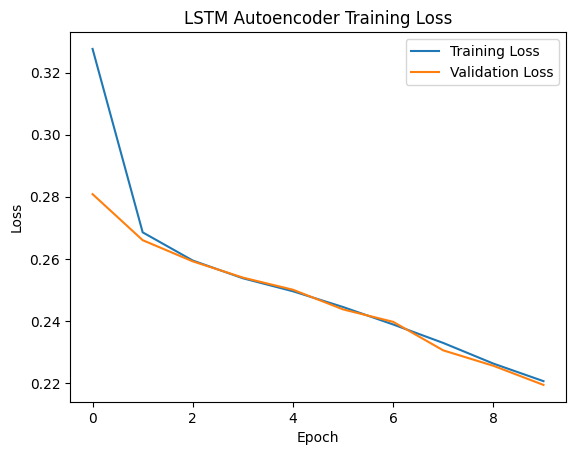

In [14]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

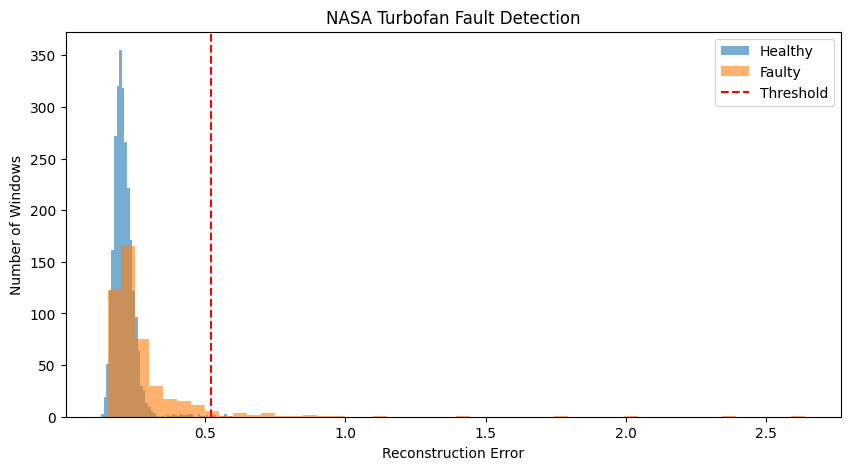

In [15]:
plt.figure(figsize=(10,5))

plt.hist(errors[y_test == 0], bins=50,
         alpha=0.6, label="Healthy")

plt.hist(errors[y_test == 1], bins=50,
         alpha=0.6, label="Faulty")

plt.axvline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.title("NASA Turbofan Fault Detection")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Windows")
plt.legend()
plt.show()